<a href="https://colab.research.google.com/github/jegillis323/MAT-422/blob/main/MAT422_Section_3_5_%26_3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MAT 422 - Sections 3.5 and 3.6: K-means and Support Vector Machines

**Topics: K-means, Support Vector Machine**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

#3.5 K-means

Cluster Centers:
[[-2.60516878  8.99280115]
 [-6.85126211 -6.85031833]
 [ 4.68687447  2.01434593]
 [-8.83456141  7.24430734]]
Intertia: 203.89074684058335


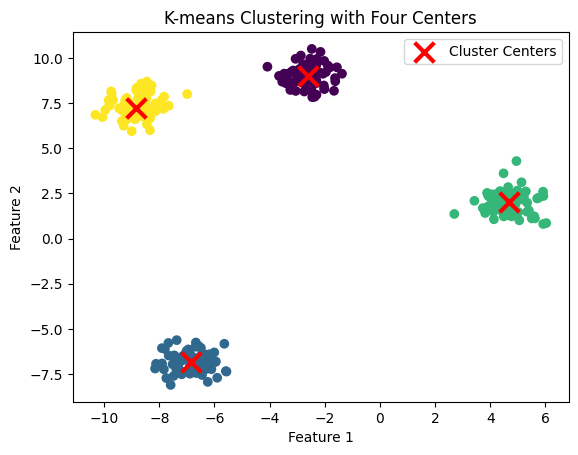

Cluster Centers:
[[-7.78596334  2.22127978]
 [ 3.33859747  0.87921433]
 [-7.19279605 -5.16569876]
 [-3.52370871  7.15108746]
 [-9.36436508  4.70587083]]
Intertia: 212.68431640498798


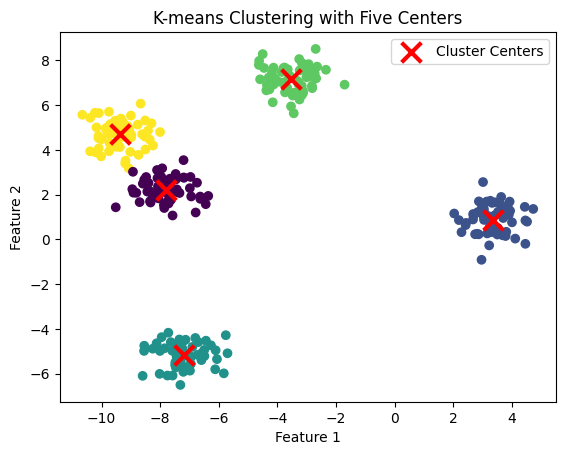

In [10]:
X_1, true_labels = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

k_means_4 = KMeans(n_clusters=4, n_init=10, random_state=42)

clusters_labels = k_means_4.fit_predict(X_1)

print("Cluster Centers:")
print(k_means_4.cluster_centers_)
print("Intertia:", k_means_4.inertia_)

plt.scatter(X_1[:, 0], X_1[:, 1], c=clusters_labels, cmap='viridis')
plt.scatter(k_means_4.cluster_centers_[:, 0], k_means_4.cluster_centers_[:, 1], marker='x', s=200, linewidths=3, color='r', label="Cluster Centers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-means Clustering with Four Centers")
plt.legend()
plt.show()

X_2, true_labels = make_blobs(n_samples=300, centers=5, cluster_std=0.60, random_state=43)

k_means_5 = KMeans(n_clusters=5, n_init=10, random_state=43)

clusters_labels = k_means_5.fit_predict(X_2)

print("Cluster Centers:")
print(k_means_5.cluster_centers_)
print("Intertia:", k_means_5.inertia_)

plt.scatter(X_2[:, 0], X_2[:, 1], c=clusters_labels, cmap='viridis')
plt.scatter(k_means_5.cluster_centers_[:, 0], k_means_5.cluster_centers_[:, 1], marker='x', s=200, linewidths=3, color='r', label="Cluster Centers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-means Clustering with Five Centers")
plt.legend()
plt.show()

My Explanation: K-means is a machine learning algorithm that groups points into K number of groups. For an example of this, 300 points are created to be around certain areas which are then categorized into different groups through the K-mean process. The graphs shows the 300 generated points grouped together into either 4 or 5 groups by color with the center of the clusters being labeled with the X. These centers are chosen by the algorithm to reduce the inertia, found by $\sum(distance\ from \ point \ to \ center)^2$. The k-means process' goal of choosing the centers is to reduce the inertia, which allows it to accurately place the centers and classify the points.

#3.6 Vector Support Machines

Training accuracy: 1.0
Support vectors per class: [9 8]
Total support vectors: 17


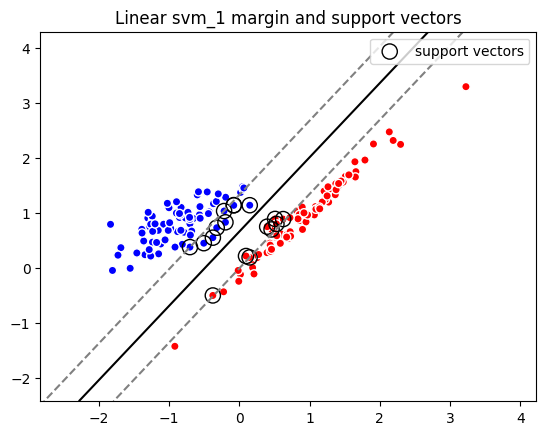

Training accuracy: 1.0
Support vectors per class: [2 3]
Total support vectors: 5


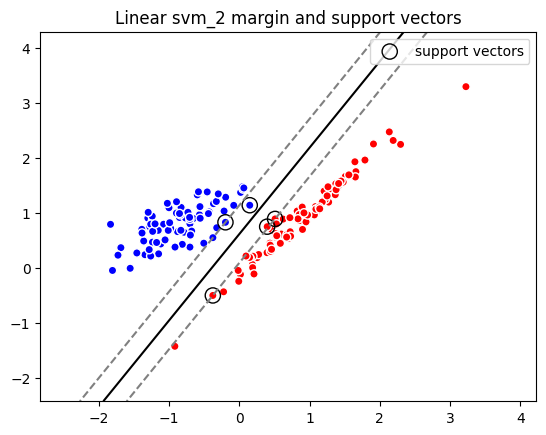

In [12]:
Xc_1, yc_1 = make_classification(n_samples=160, n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=1, class_sep=0.8, random_state=42)

svm_1 = SVC(kernel="linear", C=0.5)
svm_1.fit(Xc_1, yc_1)

predictions = svm_1.predict(Xc_1)

print("Training accuracy:", accuracy_score(yc_1, predictions))
print("Support vectors per class:", svm_1.n_support_)
print("Total support vectors:", len(svm_1.support_vectors_))

xx, yy = np.meshgrid(np.linspace(Xc_1[:,0].min()-1, Xc_1[:,0].max()+1, 150),
                     np.linspace(Xc_1[:,1].min()-1, Xc_1[:,1].max()+1, 150))
Z = svm_1.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc_1[:,0], Xc_1[:,1], c=yc_1, cmap="bwr", edgecolor="white")
plt.scatter(svm_1.support_vectors_[:,0], svm_1.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear svm_1 margin and support vectors")
plt.legend()
plt.show()

Xc_2, yc_2 = make_classification(n_samples=160, n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=1, class_sep=0.8, random_state=42)

svm_2 = SVC(kernel="linear", C=5.0)
svm_2.fit(Xc_2, yc_2)

predictions = svm_2.predict(Xc_2)

print("Training accuracy:", accuracy_score(yc_2, predictions))
print("Support vectors per class:", svm_2.n_support_)
print("Total support vectors:", len(svm_2.support_vectors_))

xx, yy = np.meshgrid(np.linspace(Xc_2[:,0].min()-1, Xc_2[:,0].max()+1, 150),
                     np.linspace(Xc_2[:,1].min()-1, Xc_2[:,1].max()+1, 150))
Z = svm_2.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc_2[:,0], Xc_2[:,1], c=yc_2, cmap="bwr", edgecolor="white")
plt.scatter(svm_2.support_vectors_[:,0], svm_2.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear svm_2 margin and support vectors")
plt.legend()
plt.show()

My Explanation: Support Vector Machines (SVM) is a learning machine algorithm that can help separate two different classes of points while also keeping a distance between the separation and the points themselves. Not all of the points in each group is considered as useful as the others, the support vectors that are circled are more important in finding the correct placement of the decision boundary line (solid line). The dashed lines to the left and right of the line represent the margins, where the points that are the closest to the boundary lie. The variable $C$ is important because it changes the tolerance of the margins. In the first graph, $C=0.5$, so the margins are more tolerant. This can be seen as more of the points are support vectors, though this can have the potential of more mistakes. The second graph has $C=5$, so the margins are less tolerant and have less support vectors. While there is a smaller likelihood of mistakes, the mistakes would be more penalized. However, both graphs are accurate in their training.